In [6]:
# Section 2: Data Loading and Initial Inspection

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pandas display settings for better readability
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_PATH = Path("../../data/prices.csv")

# Load raw dataset
df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset Dimensions: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
display(df_raw.head())

Dataset Dimensions: 61,790 rows, 16 columns


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,400.00,0.41
1,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (chicken),94,KG,actual,Retail,MMK,3636.36,3.74
2,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (pork),140,KG,actual,Retail,MMK,3636.36,3.74
3,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,miscellaneous food,Salt,185,KG,actual,Retail,MMK,242.42,0.25
4,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,vegetables and fruits,Onions,173,KG,actual,Retail,MMK,969.70,1.00


In [7]:
# Section 2: Data Loading and Initial Inspection

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pandas display settings for better readability
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_PATH = Path("../../data/prices.csv")

# Load raw dataset
df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset Dimensions: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
display(df_raw.head())

Dataset Dimensions: 61,790 rows, 16 columns


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,400.00,0.41
1,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (chicken),94,KG,actual,Retail,MMK,3636.36,3.74
2,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (pork),140,KG,actual,Retail,MMK,3636.36,3.74
3,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,miscellaneous food,Salt,185,KG,actual,Retail,MMK,242.42,0.25
4,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,vegetables and fruits,Onions,173,KG,actual,Retail,MMK,969.70,1.00


In [8]:
# Standardize column names and parse dates
df = df_raw.copy()
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Parse date column
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Check missing values and exact duplicates
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().sum() / len(df) * 100).round(2)
})
display(missing_summary)

print(f"Exact Duplicate Rows: {df.duplicated().sum():,}")
print(f"Date Range: {df['date'].min().strftime('%Y-%m')} to {df['date'].max().strftime('%Y-%m')}")

,missing_count,missing_pct
date,0,0.0
admin1,0,0.0
admin2,0,0.0
market,0,0.0
market_id,0,0.0
latitude,0,0.0
longitude,0,0.0
category,0,0.0
commodity,0,0.0
commodity_id,0,0.0


Exact Duplicate Rows: 0
Date Range: 2008-01 to 2026-09


In [9]:
# Section 3: Data Filtering

# Filter dataset based on established project scope
rice_df = df[
    (df["commodity"] == "Rice (low quality)") &
    (df["unit"] == "KG") &
    (df["pricetype"] == "Retail") &
    (df["currency"] == "MMK")
].copy()

print(f"Filtered Rice Observations: {len(rice_df):,} rows (from {len(df_raw):,} raw records)")

Filtered Rice Observations: 10,231 rows (from 61,790 raw records)


In [10]:
# Section 4: Monthly Aggregation

rice_df["month"] = rice_df["date"].dt.to_period("M")

# Aggregate by market and month
monthly_rice = (
    rice_df.groupby(["market_id", "market", "month"])
    .agg(
        monthly_price=("price", "mean"),
        obs_count=("price", "size")
    )
    .reset_index()
)

# Verify single observation per market per month
duplicates = monthly_rice.duplicated(subset=["market_id", "month"]).sum()
print(f"Duplicate market-month pairs after aggregation: {duplicates}")
display(monthly_rice.head())

Duplicate market-month pairs after aggregation: 0


,market_id,market,month,monthly_price,obs_count
0,977,Alel Than Kyaw,2008-01,460.0,1
1,977,Alel Than Kyaw,2008-02,450.0,1
2,977,Alel Than Kyaw,2008-03,440.0,1
3,977,Alel Than Kyaw,2008-04,480.0,1
4,977,Alel Than Kyaw,2008-05,480.0,1


In [11]:
# Section 5: Calculate Coverage Statistics Per Market

market_coverage = (
    monthly_rice.groupby(["market_id", "market"])
    .agg(
        first_month=("month", "min"),
        last_month=("month", "max"),
        unique_months=("month", "nunique")
    )
    .reset_index()
)

# Calculate calendar span in months between first and last observation
market_coverage["span_months"] = (
    (market_coverage["last_month"].dt.year - market_coverage["first_month"].dt.year) * 12
    + (market_coverage["last_month"].dt.month - market_coverage["first_month"].dt.month) + 1
)

# Calculate coverage percentage relative to individual observation span
market_coverage["coverage_pct"] = (
    (market_coverage["unique_months"] / market_coverage["span_months"]) * 100
).round(1)

# Sort by total unique months
market_coverage = market_coverage.sort_values("unique_months", ascending=False).reset_index(drop=True)

display(market_coverage.head(15))

,market_id,market,first_month,last_month,unique_months,span_months,coverage_pct
0,1658,Lashio Market,2008-01,2026-09,202,225,89.8
1,978,Buthidaung,2008-01,2026-08,162,224,72.3
2,1664,Pakokku Myo Ma Market,2014-01,2026-09,146,153,95.4
3,983,Hakha Myoma Market,2010-06,2025-03,139,178,78.1
4,997,Magway,2008-01,2020-03,135,147,91.8
5,1661,Kutkai,2014-01,2026-09,130,153,85.0
6,1370,Tedim Municipal Market,2012-01,2025-02,124,158,78.5
7,1014,Rathedaung,2008-01,2026-09,123,225,54.7
8,1657,Shwegu,2014-01,2025-02,123,134,91.8
9,1020,Tonzang,2010-06,2025-02,121,177,68.4


In [12]:
# Identify initial candidates based on screening criteria:
# 1. At least 36 unique observed months
# 2. Latest observation in 2026

candidate_markets = market_coverage[
    (market_coverage["unique_months"] >= 36) &
    (market_coverage["last_month"].dt.year == 2026)
].copy()

print(f"Total Candidate Markets Meeting Initial Criteria: {len(candidate_markets)}")

Total Candidate Markets Meeting Initial Criteria: 57


In [13]:
# Section 6: Analyze Observation Intervals and Internal Gaps for Key Candidates

def analyze_market_gaps(df_monthly, market_id):
    m_data = df_monthly[df_monthly["market_id"] == market_id].sort_values("month")
    
    # Complete expected monthly sequence
    full_idx = pd.period_range(start=m_data["month"].min(), end=m_data["month"].max(), freq="M")
    obs_idx = pd.PeriodIndex(m_data["month"], freq="M")
    
    missing_months = full_idx.difference(obs_idx)
    
    # Calculate intervals between consecutive observations in months
    m_data["next_month"] = m_data["month"].shift(-1)
    m_data["gap_size"] = (m_data["next_month"] - m_data["month"]).apply(lambda x: x.n if pd.notnull(x) else 1)
    
    long_gaps = m_data[m_data["gap_size"] > 2][["month", "next_month", "gap_size"]]
    
    return len(missing_months), long_gaps

# Example inspection for primary candidates
for m_id in [1658, 1664, 1005, 1019]:
    m_name = candidate_markets[candidate_markets["market_id"] == m_id]["market"].values[0]
    n_missing, gaps = analyze_market_gaps(monthly_rice, m_id)
    print(f"Market: {m_name} (ID: {m_id}) | Missing Months in Span: {n_missing}")
    if not gaps.empty:
        print("  Significant Gaps (>2 consecutive missing months):")
        for _, row in gaps.iterrows():
            print(f"    From {row['month']} to {row['next_month']}: Gap of {row['gap_size'] - 1} missing months")
    else:
        print("  No gaps > 2 months found.")
    print("-" * 60)

Market: Lashio Market (ID: 1658) | Missing Months in Span: 23
  Significant Gaps (>2 consecutive missing months):
    From 2011-12 to 2012-03: Gap of 2 missing months
    From 2012-06 to 2012-10: Gap of 3 missing months
    From 2013-05 to 2013-08: Gap of 2 missing months
    From 2018-06 to 2018-09: Gap of 2 missing months
    From 2024-05 to 2024-08: Gap of 2 missing months
------------------------------------------------------------
Market: Pakokku Myo Ma Market (ID: 1664) | Missing Months in Span: 7
  Significant Gaps (>2 consecutive missing months):
    From 2015-04 to 2015-08: Gap of 3 missing months
    From 2019-04 to 2019-07: Gap of 2 missing months
------------------------------------------------------------
Market: Momauk (ID: 1005) | Missing Months in Span: 68
  Significant Gaps (>2 consecutive missing months):
    From 2011-06 to 2014-01: Gap of 30 missing months
    From 2020-03 to 2020-07: Gap of 3 missing months
    From 2020-11 to 2021-04: Gap of 4 missing months
    F

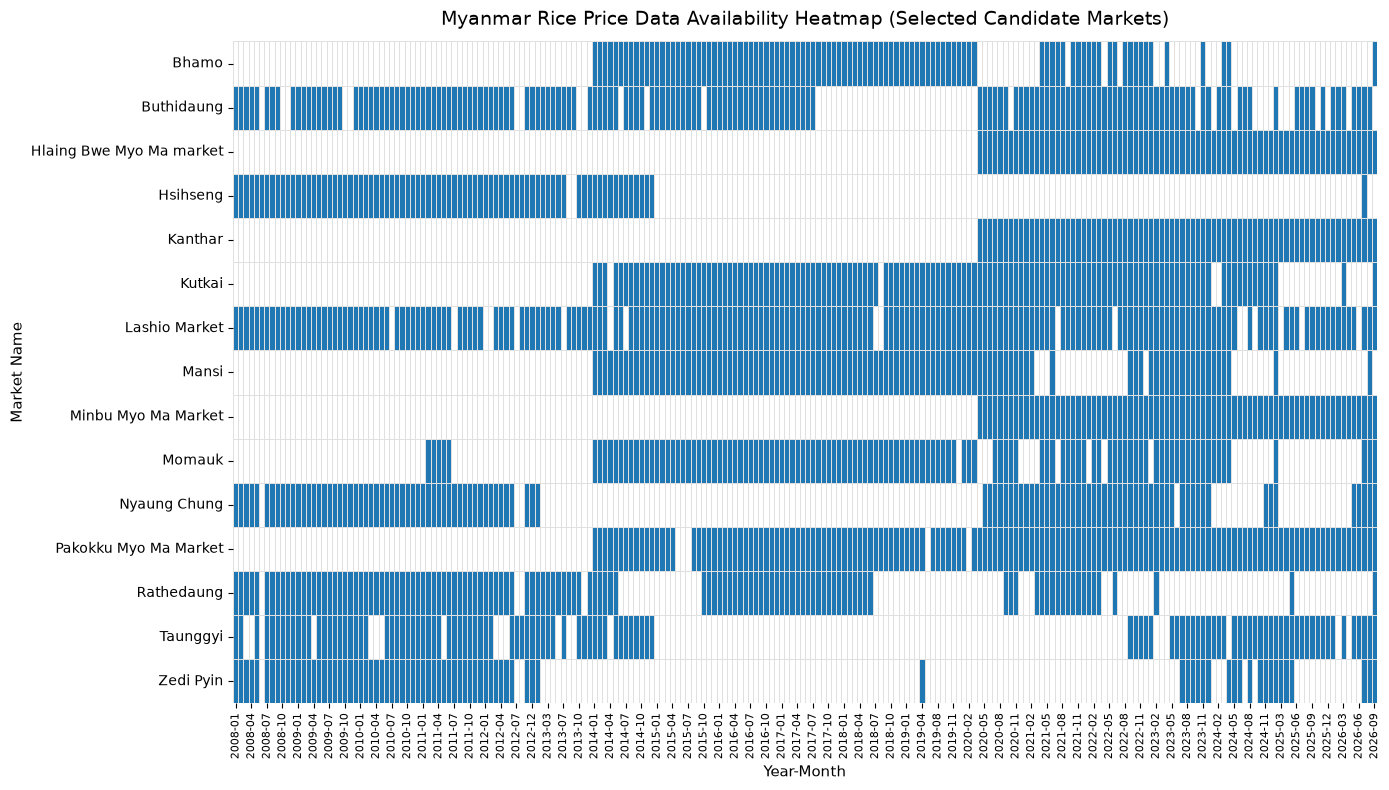

In [14]:
# Section 7: Data Availability Heatmap

# Pivot data to create a Market x Time matrix for top candidates
selected_ids = candidate_markets.head(15)["market_id"].tolist()
pivot_df = monthly_rice[monthly_rice["market_id"].isin(selected_ids)].pivot(
    index="month",
    columns="market",
    values="monthly_price"
)

# Convert PeriodIndex to String for plotting
pivot_df.index = pivot_df.index.astype(str)

# Generate binary availability matrix: 1 = Data Present, 0 = Missing
availability_matrix = pivot_df.notnull().astype(int)

plt.figure(figsize=(14, 8))
# Custom cmap: 0 (white/missing), 1 (blue/present)
sns.heatmap(
    availability_matrix.T, 
    cmap=["#ffffff", "#1f77b4"], 
    cbar=False, 
    linewidths=0.5, 
    linecolor="#e0e0e0"
)

plt.title("Myanmar Rice Price Data Availability Heatmap (Selected Candidate Markets)", fontsize=14, pad=12)
plt.xlabel("Year-Month", fontsize=11)
plt.ylabel("Market Name", fontsize=11)
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
# Extension: Quantitative Market Ranking by Observation Density and Smallest Gaps

gap_metrics = []

for market_id, group in monthly_rice.groupby("market_id"):
    m_name = group["market"].iloc[0]
    group_sorted = group.sort_values("month")
    
    # Total unique monthly observations
    total_obs = len(group_sorted)
    
    # Expected full monthly period range from start to end date
    start_m = group_sorted["month"].min()
    end_m = group_sorted["month"].max()
    full_range = pd.period_range(start=start_m, end=end_m, freq="M")
    
    # Total possible months in span
    span_length = len(full_range)
    
    # Internal missing months (gaps)
    obs_months = pd.PeriodIndex(group_sorted["month"], freq="M")
    missing_months = full_range.difference(obs_months)
    num_missing = len(missing_months)
    
    # Calculate continuous internal gap lengths
    group_sorted = group_sorted.copy()
    group_sorted["next_month"] = group_sorted["month"].shift(-1)
    group_sorted["gap_diff"] = (group_sorted["next_month"] - group_sorted["month"]).apply(
        lambda x: x.n - 1 if pd.notnull(x) and x.n > 1 else 0
    )
    
    max_internal_gap = group_sorted["gap_diff"].max()
    sum_internal_gaps = group_sorted["gap_diff"].sum()
    
    gap_metrics.append({
        "market_id": market_id,
        "market": m_name,
        "total_observations": total_obs,
        "span_months": span_length,
        "missing_internal_months": num_missing,
        "max_single_gap": max_internal_gap,
        "continuity_score": round((total_obs / span_length) * 100, 2)
    })

df_gaps = pd.DataFrame(gap_metrics)

# Sort logic: Maximize total observations AND maximize continuity score (minimize gaps)
df_optimized = df_gaps.sort_values(
    by=["total_observations", "continuity_score"], 
    ascending=[False, False]
).reset_index(drop=True)

print("Top 10 Markets Ranked by High Observation Volume & Smallest Gaps:")
display(df_optimized.head(10))

Top 10 Markets Ranked by High Observation Volume & Smallest Gaps:


,market_id,market,total_observations,span_months,missing_internal_months,max_single_gap,continuity_score
0,1658,Lashio Market,202,225,23,3,89.78
1,978,Buthidaung,162,224,62,32,72.32
2,1664,Pakokku Myo Ma Market,146,153,7,3,95.42
3,983,Hakha Myoma Market,139,178,39,20,78.09
4,997,Magway,135,147,12,3,91.84
5,1661,Kutkai,130,153,23,12,84.97
6,1370,Tedim Municipal Market,124,158,34,25,78.48
7,1657,Shwegu,123,134,11,7,91.79
8,1014,Rathedaung,123,225,102,26,54.67
9,1020,Tonzang,121,177,56,25,68.36


In [16]:
df_optimized.sort_values

<bound method DataFrame.sort_values of      market_id                 market  total_observations  span_months  \
0         1658          Lashio Market                 202          225   
1          978             Buthidaung                 162          224   
2         1664  Pakokku Myo Ma Market                 146          153   
3          983     Hakha Myoma Market                 139          178   
4          997                 Magway                 135          147   
..         ...                    ...                 ...          ...   
293      10255          Hpon Nyo Leik                   1            1   
294      10795         Pa Tein Ta Lan                   1            1   
295      10796                 Lailen                   1            1   
296      10797              Ngaphaipi                   1            1   
297      11185                 Kawlin                   1            1   

     missing_internal_months  max_single_gap  continuity_score  
0      

In [17]:
market_ids_array = df_optimized["market_id"].to_numpy()
market_ids_list = df_optimized["market_id"].tolist()

print("Descending Array of Market IDs (Best to Worst):")
print(market_ids_array)

Descending Array of Market IDs (Best to Worst):
[ 1658   978  1664   983   997  1661  1370  1657  1014  1020  1005  1000
  1012  1002  1019  1021  1656  1010  1655  1023   988  1001  1015  1382
   986  3280  3302  3308  1024   981  3297  3354  1482  3299  3281  3346
  3276  5225  3321  1662  3353  6087  6089  6090  3326  3626  3304  6085
  6088  6091  3285   989   998  3352  6377  3315   980   990   993  1017
  1018  3332  6086  3320  1013  3348  3312  1670  1659  3288  6376  3289
  3307  5230  3313  3347  8028  6077  5231  3309  3306  3334  5229  6084
  3292  3311  1663  7928  3338  3305  3294   995  3278  3293  3323  3337
  3279  7443  5602  3277  3327  3345  1667  1668  8027  7930  3317  1653
  8551  3286  3341  8470  3310  3283  3333   977  9094  3282  3336  3331
  7924  1008  3290  5232  1011   999  1669  7920  3319  7925  6079  3301
  3287   982  3325  3274  1022   985  6374  6078  5244   984  7921  8467
  8401  1353  1654  9717  1009  3316  3328  1003  1660  9028  7923  1373
   

In [18]:
# Create a complete monthly timeline
all_months = pd.period_range(
    monthly_rice["month"].min(),
    monthly_rice["month"].max(),
    freq="M"
)

# Create market-month price matrix
price_matrix = (
    monthly_rice
    .pivot(
        index="market",
        columns="month",
        values="monthly_price"
    )
    .reindex(columns=all_months)
)

# 1 = Missing, 0 = Observed
missing_matrix = price_matrix.isna().astype(int)

display(missing_matrix.head())

,2008-01,2008-02,2008-03,2008-04,2008-05,2008-06,2008-07,2008-08,2008-09,2008-10,2008-11,2008-12,2009-01,2009-02,2009-03,2009-04,2009-05,2009-06,2009-07,2009-08,2009-09,2009-10,2009-11,2009-12,2010-01,2010-02,2010-03,2010-04,2010-05,2010-06,2010-07,2010-08,2010-09,2010-10,2010-11,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12,2012-01,2012-02,...,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
market,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
88 ward,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
Ah Nauk Pyin,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
Ah Nauk Ywe,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,...,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1
Ahpauk Wa,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,...,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
Ai Cheng,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


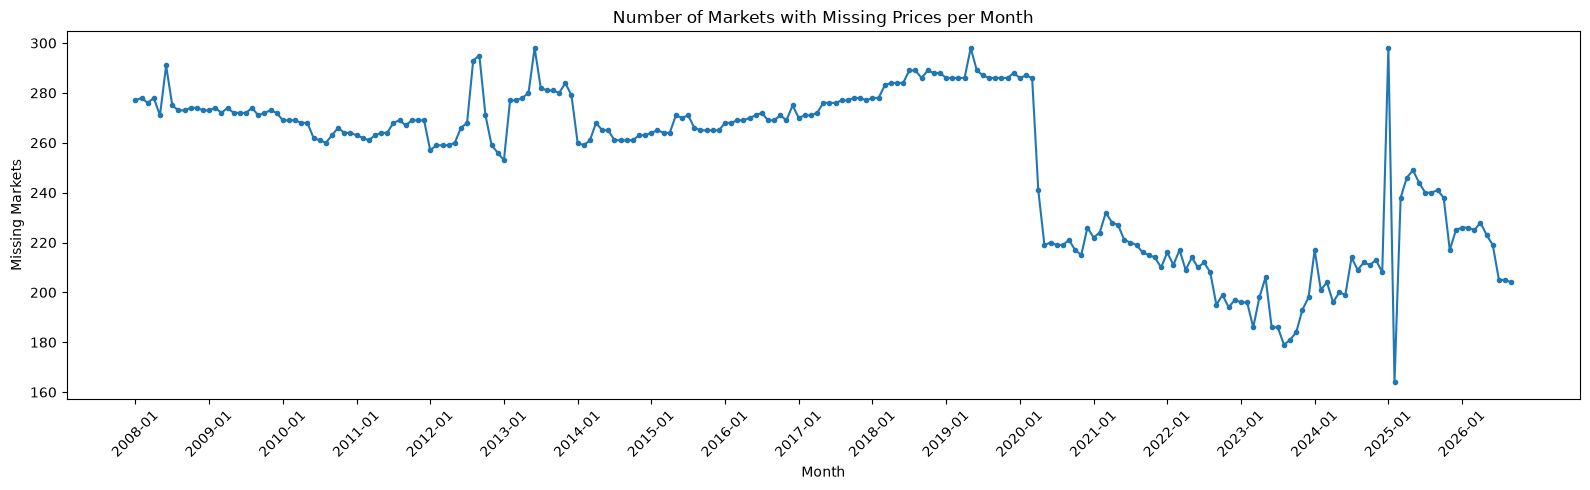

In [19]:
monthly_missing_count = missing_matrix.sum(axis=0)

plt.figure(figsize=(16, 5))

plt.plot(
    monthly_missing_count.index.astype(str),
    monthly_missing_count.values,
    marker="o",
    markersize=3
)

plt.title("Number of Markets with Missing Prices per Month")
plt.xlabel("Month")
plt.ylabel("Missing Markets")

plt.xticks(
    ticks=range(0, len(monthly_missing_count), 12),
    labels=monthly_missing_count.index.astype(str)[::12],
    rotation=45
)

plt.tight_layout()
plt.show()